# 🐼📈 Pandas і графіки для аналітиків · Блокнот 3 з 7
## Нові стовпці та очищення даних · 📈 Графіки для перевірки даних

Цей блокнот складається з двох частин:

**Частина А. Нові стовпці.** Рахуємо нові показники з тих, що вже є: виручку, ціну в доларах, розмір замовлення, регіон. Це як формули в Excel, тільки одна формула відразу для всієї таблиці.

**Частина Б. Очищення даних.** Справжні дані майже ніколи не бувають ідеальними: дублікати, «kyiv» і «Kyiv » як різні міста, ціни з текстом «UAH», порожні клітинки. Аналітики кажуть, що очищення забирає до 80% часу, тому це дуже важлива навичка.

**📈 Графіки для перевірки даних.** Графік — найшвидший спосіб побачити проблему в даних. Навчимося:
- ставити **кілька графіків поруч** (`plt.subplots`), щоб порівнювати «до» і «після»;
- малювати **лінії-орієнтири** на графіку (`plt.axvline`);
- будувати «карту пропусків».

### Як працювати з блокнотом
- Запускайте клітинки **по черзі зверху вниз**: кнопка ▶ ліворуч або **`Shift + Enter`**.
- **Першою** запустіть клітинку «📦 Підготовка даних»: вона створить файли з даними.
- Змінюйте числа й умови в прикладах і дивіться, що вийде. Зламати нічого не можна.
- У практиці пишіть код у клітинках «Ваш код тут». Розв'язки всіх завдань зібрані в **останній клітинці** блокнота. Спершу спробуйте самостійно, а туди зазирайте, лише якщо справді застрягли.
- Розділи з позначкою **📈** — про графіки. Вони йдуть паралельно з pandas і поступово ускладнюються від блокнота до блокнота.

<details>
<summary><b>📚 Увесь курс</b></summary>

01. Знайомство з pandas · 📈 Перший графік<br>02. Вибір, фільтрація та сортування · 📈 Налаштовуємо вигляд графіка<br>**03. Нові стовпці та очищення даних · 📈 Графіки для перевірки даних** ← ви тут<br>04. Групування та зведені таблиці · 📈 Графіки з групувань<br>05. Об'єднання таблиць · 📈 Порівняння і зв'язки<br>06. Робота з датами · 📈 Графіки динаміки<br>07. Фінальний проєкт · 📈 Дашборд для керівника

</details>

## Крок 0. Готуємо дані

In [1]:
# @title 📦 Підготовка даних — просто запустіть цю клітинку (Shift + Enter)
# Ця клітинка створює навчальні файли з даними інтернет-магазину за 2025 рік.
# Розбиратися в її коді не потрібно.
# Якщо Colab перезапустився і файли зникли — просто запустіть її ще раз.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2025)

# ---------- Товари ----------
products = pd.DataFrame([
    ("P01", "Headphones",         "Electronics", 1500,  900),
    ("P02", "Power bank",         "Electronics",  900,  520),
    ("P03", "Smartwatch",    "Electronics", 4200, 2900),
    ("P04", "Bluetooth speaker", "Electronics", 2100, 1300),
    ("P05", "T-shirt",          "Clothing",         450,  180),
    ("P06", "Hoodie",              "Clothing",        1200,  550),
    ("P07", "Jeans",            "Clothing",        1600,  800),
    ("P08", "Sneakers",          "Clothing",        2800, 1600),
    ("P09", "Mug",             "Home",          180,   60),
    ("P10", "Blanket",              "Home",          850,  400),
    ("P11", "Desk lamp",   "Home",         1100,  600),
    ("P12", "Towel set",    "Home",          650,  300),
    ("P13", "Face cream",  "Beauty",        520,  210),
    ("P14", "Shampoo",           "Beauty",        260,  110),
    ("P15", "Perfume",           "Beauty",       2400, 1300),
    ("P16", "Yoga mat",  "Sports",        700,  320),
    ("P17", "Water bottle",   "Sports",        350,  140),
    ("P18", "Dumbbells 5 kg",      "Sports",        950,  550),
], columns=["product_id", "product", "category", "price", "cost"])

# ---------- Клієнти ----------
n_cust = 400
names = ["Olena", "Andrii", "Mariia", "Ihor", "Nataliia", "Dmytro", "Iryna", "Oleksandr",
         "Tetiana", "Serhii", "Yuliia", "Maksym", "Oksana", "Viktor", "Anna", "Bohdan",
         "Kateryna", "Taras", "Sofiia", "Roman"]
cities = ["Kyiv", "Lviv", "Odesa", "Kharkiv", "Dnipro"]
reg = pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 3 * 365, n_cust), unit="D")
customers = pd.DataFrame({
    "customer_id": [f"C{i:04d}" for i in range(1, n_cust + 1)],
    "name": rng.choice(names, n_cust),
    "city": rng.choice(cities, n_cust, p=[0.35, 0.2, 0.15, 0.15, 0.15]),
    "age": np.clip(rng.normal(33, 9, n_cust).round(), 18, 65).astype(int),
    "registration_date": reg.strftime("%Y-%m-%d"),
})

# ---------- Замовлення ----------
n = 3000
days = pd.date_range("2025-01-01", "2025-12-31")
w = np.linspace(0.85, 1.15, len(days))          # магазин поступово росте
w[days.month.isin([6, 7, 8])] *= 0.8            # влітку спокійніше
w[days.month.isin([11, 12])] *= 1.5             # сезон розпродажів і свят
w[days.dayofweek >= 5] *= 1.3                   # у вихідні купують більше
w[days == pd.Timestamp("2025-11-28")] *= 6      # Чорна п'ятниця
order_date = pd.DatetimeIndex(np.sort(rng.choice(days.values, n, p=w / w.sum())))

cust_w = rng.gamma(1.0, 1, n_cust)
cust_idx = rng.choice(n_cust, n, p=cust_w / cust_w.sum())
prod_w = 1 / np.sqrt(products["price"].to_numpy())
prod_idx = rng.choice(len(products), n, p=prod_w / prod_w.sum())

quantity = rng.choice([1, 2, 3, 4], n, p=[0.72, 0.18, 0.07, 0.03])
payment = rng.choice(["Card", "Cash on delivery", "Google/Apple Pay"], n, p=[0.55, 0.27, 0.18])
channel = rng.choice(["Website", "App", "Instagram"], n, p=[0.5, 0.35, 0.15])

cod = payment == "Cash on delivery"
u = rng.random(n)
status = np.where(u < np.where(cod, 0.80, 0.91), "Delivered",
                  np.where(u < np.where(cod, 0.92, 0.96), "Cancelled", "Returned"))

city = customers["city"].to_numpy()[cust_idx]
deliv_days = np.where(city == "Kyiv", rng.integers(1, 3, n), rng.integers(1, 6, n))
delivery = order_date + pd.to_timedelta(deliv_days, unit="D")
delivery_str = np.where(status == "Cancelled", None, delivery.strftime("%Y-%m-%d"))

rating = np.where(deliv_days >= 4,
                  rng.choice(5, n, p=[0.08, 0.12, 0.22, 0.33, 0.25]) + 1,
                  rng.choice(5, n, p=[0.03, 0.05, 0.12, 0.35, 0.45]) + 1).astype(float)
returned = status == "Returned"
rating[returned] = rng.choice([1, 2, 3], returned.sum(), p=[0.5, 0.3, 0.2])
rating[(status == "Cancelled") | (rng.random(n) > 0.6)] = np.nan

orders = pd.DataFrame({
    "order_id": np.arange(100001, 100001 + n),
    "order_date": order_date.strftime("%Y-%m-%d"),
    "delivery_date": delivery_str,
    "customer_id": customers["customer_id"].to_numpy()[cust_idx],
    "product_id": products["product_id"].to_numpy()[prod_idx],
    "quantity": quantity,
    "payment": payment,
    "channel": channel,
    "status": status,
    "rating": rating,
})

# ---------- Одна велика таблиця продажів ----------
sales = (orders.merge(customers[["customer_id", "city"]], on="customer_id", how="left")
               .merge(products[["product_id", "product", "category", "price"]], on="product_id", how="left"))
sales = sales[["order_id", "order_date", "delivery_date", "customer_id", "city", "category",
               "product", "price", "quantity", "payment", "channel", "status", "rating"]]
sales = sales.sort_values("order_id").reset_index(drop=True)

# ---------- Квартальні вивантаження ----------
quarter = pd.to_datetime(sales["order_date"]).dt.quarter
for q in range(1, 5):
    sales[quarter == q].to_csv(f"sales_2025_Q{q}.csv", index=False)

# ---------- «Брудне» вивантаження продажів ----------
raw = sales.copy()
raw["price"] = raw["price"].astype(str) + " UAH"
raw["order_date"] = pd.to_datetime(raw["order_date"]).dt.strftime("%d.%m.%Y")
raw["delivery_date"] = pd.to_datetime(raw["delivery_date"]).dt.strftime("%d.%m.%Y")
messy = {"Kyiv": ["kyiv", "KYIV", " Kyiv", "Kiev"], "Lviv": ["lviv", "Lviv ", " LVIV"],
         "Odesa": ["odesa", "Odesa "], "Kharkiv": ["kharkiv", "KHARKIV "], "Dnipro": ["dnipro", " Dnipro"]}
city_col = raw["city"].to_numpy(dtype=object)
for i in rng.choice(n, 300, replace=False):
    city_col[i] = rng.choice(messy[city_col[i]])
city_col[rng.choice(n, 15, replace=False)] = None
raw["city"] = city_col
qty_col = raw["quantity"].to_numpy(dtype=float)
qty_col[rng.choice(n, 40, replace=False)] = np.nan
raw["quantity"] = qty_col
pay_col = raw["payment"].to_numpy(dtype=object)
pay_col[rng.choice(n, 60, replace=False)] = None
raw["payment"] = pay_col
raw = pd.concat([raw, raw.iloc[rng.choice(n, 25, replace=False)]])
raw = raw.sort_values("order_id", kind="stable").reset_index(drop=True)
raw.columns = ["Order ID", "Order Date", "Delivery Date", "Customer ID", "City", "Category",
               "Product", "Price", "Qty", "Payment", "Channel", "Status", "Rating"]

# ---------- «Брудний» список клієнтів ----------
craw = customers.copy()
name_col = craw["name"].to_numpy(dtype=object)
for i in rng.choice(n_cust, 40, replace=False):
    name_col[i] = rng.choice([name_col[i].lower(), name_col[i].upper(), " " + name_col[i] + " "])
craw["name"] = name_col
cc = craw["city"].to_numpy(dtype=object)
for i in rng.choice(n_cust, 50, replace=False):
    cc[i] = rng.choice([cc[i].lower(), cc[i].upper(), cc[i] + " "])
craw["city"] = cc
age_col = craw["age"].to_numpy(dtype=float)
age_col[rng.choice(n_cust, 12, replace=False)] = np.nan
craw["age"] = age_col
craw["registration_date"] = pd.to_datetime(craw["registration_date"]).dt.strftime("%d/%m/%Y")
craw = pd.concat([craw, craw.iloc[rng.choice(n_cust, 8, replace=False)]])
craw = craw.sort_values("customer_id", kind="stable").reset_index(drop=True)

# ---------- Зберігаємо файли ----------
sales.to_csv("sales.csv", index=False)
orders.to_csv("orders.csv", index=False)
customers.to_csv("customers.csv", index=False)
products.to_csv("products.csv", index=False)
raw.to_csv("sales_raw.csv", index=False)
craw.to_csv("customers_raw.csv", index=False)

# ---------- Налаштування вигляду таблиць і стиль графіків (з блокнота 2) ----------
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.3,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]),
})

del (rng, names, cities, reg, n, n_cust, days, w, order_date, cust_w, cust_idx, prod_w, prod_idx,
     quantity, payment, channel, cod, u, status, city, deliv_days, delivery, delivery_str, rating,
     returned, quarter, q, raw, messy, city_col, qty_col, pay_col, craw, name_col, cc, age_col, i,
     sales, orders, customers, products)

print("✅ Done! Data files created:")
print("   sales.csv, orders.csv, customers.csv, products.csv,")
print("   sales_raw.csv, customers_raw.csv, sales_2025_Q1…Q4.csv")

✅ Done! Data files created:
   sales.csv, orders.csv, customers.csv, products.csv,
   sales_raw.csv, customers_raw.csv, sales_2025_Q1…Q4.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("sales.csv")
df.head(3)

,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
0,100001,2025-01-01,NaN,C0230,Kyiv,Sports,Dumbbells 5 kg,950,4,Card,Website,Cancelled,NaN
1,100002,2025-01-01,2025-01-02,C0074,Odesa,Electronics,Smartwatch,4200,3,Google/Apple Pay,Website,Delivered,5.00
2,100003,2025-01-01,2025-01-05,C0216,Odesa,Electronics,Smartwatch,4200,1,Google/Apple Pay,Website,Delivered,NaN


---
# Частина А. Нові стовпці

## А1. Стовпець-формула
Новий стовпець створюється так само, як змінна: **`df["new_name"] = формула`**. Формула застосовується до **кожного рядка** одразу.

Порахуємо **виручку** (суму) кожного замовлення: ціна × кількість.

In [3]:
df["revenue"] = df["price"] * df["quantity"]

df[["product", "price", "quantity", "revenue"]].head()

,product,price,quantity,revenue
0,Dumbbells 5 kg,950,4,3800
1,Smartwatch,4200,3,12600
2,Smartwatch,4200,1,4200
3,Bluetooth speaker,2100,1,2100
4,Desk lamp,1100,1,1100


Новий стовпець з'явився в кінці таблиці. З ним можна робити все те саме, що й з іншими:

In [4]:
print("Total order value:", df["revenue"].sum(), "UAH")
print("Average order value:", df["revenue"].mean().round(2), "UAH")

Total order value: 3986620 UAH
Average order value: 1328.87 UAH


Ще приклади формул: ділення на число та округлення.

In [5]:
usd_rate = 41.5                                          # умовний курс
df["revenue_usd"] = (df["revenue"] / usd_rate).round(2)

df[["revenue", "revenue_usd"]].head()

,revenue,revenue_usd
0,3800,91.57
1,12600,303.61
2,4200,101.20
3,2100,50.60
4,1100,26.51


## А2. Стовпець за умовою: `np.where` (як «ЯКЩО» в Excel)

`np.where(умова, значення_якщо_так, значення_якщо_ні)`

Позначимо замовлення від 3000 грн як `"Large"` (велике), решту як `"Regular"` (звичайне).

In [6]:
df["order_size"] = np.where(df["revenue"] >= 3000, "Large", "Regular")

df[["product", "revenue", "order_size"]].head()

,product,revenue,order_size
0,Dumbbells 5 kg,3800,Large
1,Smartwatch,12600,Large
2,Smartwatch,4200,Large
3,Bluetooth speaker,2100,Regular
4,Desk lamp,1100,Regular


In [7]:
df["order_size"].value_counts(0)

,count
order_size,
Regular,2736
Large,264


### 📈 Гістограма з лінією-орієнтиром
Подивимося, де на розподілі сум замовлень проходить межа `"Large"`. Вертикальну лінію малює `plt.axvline(значення)`:

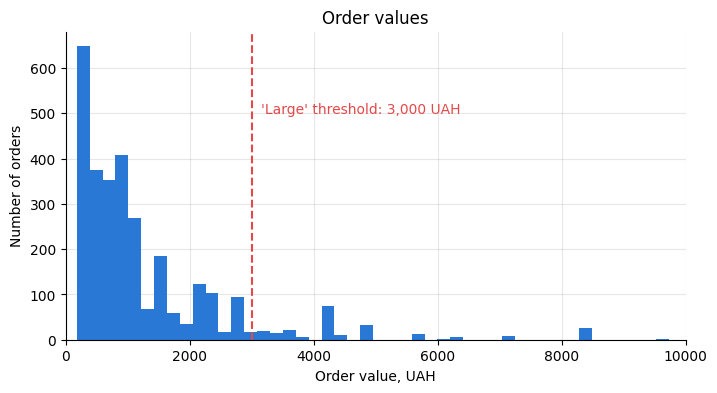

In [8]:
df["revenue"].plot(kind="hist", bins=80)
plt.axvline(3000, color="#e34948", linestyle="--", linewidth=1.5)
plt.text(3150, 500, "'Large' threshold: 3,000 UAH", color="#e34948")
plt.xlim(0, 10000)        # показуємо до 10 000 грн: рідкісні дуже великі замовлення лише «стискають» графік
plt.title("Order values")
plt.xlabel("Order value, UAH")
plt.ylabel("Number of orders")
plt.show()

Майже всі замовлення лівіше від лінії: «великих» лише близько 9%. Такий графік допомагає обирати межі свідомо, а не навмання.

💡 Що тут нового:
- `linestyle="--"` — пунктирна лінія; для горизонтальної лінії є `plt.axhline(значення)`;
- `plt.text(x, y, "text")` ставить напис у точку з координатами (x, y) прямо на графіку;
- `plt.xlim(від, до)` обмежує вісь X (для осі Y є `plt.ylim`).

## А3. Кілька груп: `pd.cut` (розбити числа на інтервали)

Коли груп більше двох, `np.where` стає незручним. `pd.cut` розкладає числа «по кошиках»:
- `bins`: межі інтервалів;
- `labels`: назви груп (їх на одну менше, ніж меж).

Розіб'ємо товари на цінові сегменти: до 500 грн, від 500 до 1500 грн і дорожче.

In [9]:
df["price_segment"] = pd.cut(
    df["price"],
    bins=[0, 500, 1500, np.inf],          # np.inf — «нескінченність», тобто без верхньої межі
    labels=["Budget", "Mid-range", "Premium"],
)

df[["product", "price", "price_segment"]].drop_duplicates("product").sort_values("price")

,product,price,price_segment
25,Mug,180,Budget
5,Shampoo,260,Budget
58,Water bottle,350,Budget
24,T-shirt,450,Budget
14,Face cream,520,Mid-range
8,Towel set,650,Mid-range
7,Yoga mat,700,Mid-range
23,Blanket,850,Mid-range
16,Power bank,900,Mid-range
0,Dumbbells 5 kg,950,Mid-range


💡 Межі читаються так: `(0, 500]` — більше 0 і **до 500 включно**; `(500, 1500]` — більше 500 і до 1500 включно.

### 📈 Скільки замовлень у кожному сегменті?

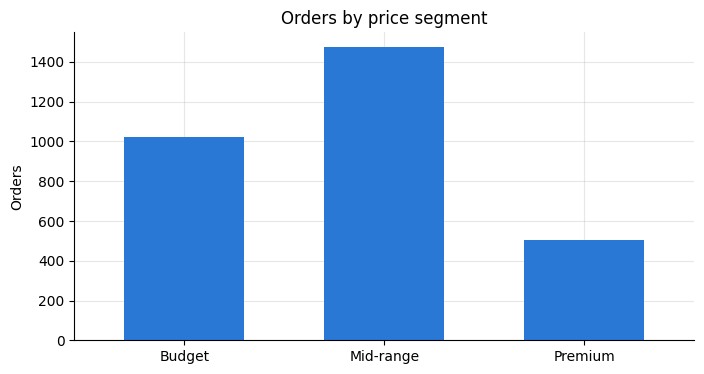

In [10]:
df["price_segment"].value_counts().sort_index().plot(kind="bar", rot=0, width=0.6)
plt.title("Orders by price segment")
plt.xlabel("")
plt.ylabel("Orders")
plt.show()

💡 `sort_index()` залишає сегменти в логічному порядку (Budget → Mid-range → Premium), а не за кількістю. Для груп, що мають природний порядок, так і треба.

## А4. Заміна за словником: `map`

Коли кожному значенню треба поставити у відповідність інше, використовуйте **словник** і `map`. Наприклад, місто → регіон:

In [11]:
region_of_city = {
    "Kyiv": "Center",
    "Lviv": "West",
    "Odesa": "South",
    "Kharkiv": "East",
    "Dnipro": "East",
}

df["region"] = df["city"].map(region_of_city)

df[["city", "region"]].drop_duplicates()

,city,region
0,Kyiv,Center
1,Odesa,South
4,Lviv,West
5,Dnipro,East
9,Kharkiv,East


⚠️ Якщо якогось значення немає в словнику, `map` поставить `NaN` (порожньо). Тому після `map` варто перевірити пропуски: `df["region"].isna().sum()`.

## А5. Перейменувати і видалити стовпці

In [12]:
# Перейменувати: словник {"old_name": "new_name"}
df = df.rename(columns={"price_segment": "segment"})

# Видалити стовпці, які більше не потрібні
df = df.drop(columns=["revenue_usd", "order_size"])

df.columns


Index(['order_id', 'order_date', 'delivery_date', 'customer_id', 'city',
       'category', 'product', 'price', 'quantity', 'payment', 'channel',
       'status', 'rating', 'revenue', 'segment', 'region'],
      dtype='object')

💡 Більшість методів pandas **не змінюють таблицю**, а повертають нову. Тому результат треба зберегти: `df = df.rename(...)`. Якщо забути `df =`, зміни «зникнуть».

---
# Частина Б. Очищення даних

Уявіть: колега надіслав вивантаження продажів з CRM, файл **`sales_raw.csv`**. Це ті самі замовлення, але «брудні». Наше завдання — привести їх до ладу.

## Б1. Дивимось на дані і шукаємо проблеми

In [13]:
raw = pd.read_csv("sales_raw.csv")
raw.head()

,Order ID,Order Date,Delivery Date,Customer ID,City,Category,Product,Price,Qty,Payment,Channel,Status,Rating
0,100001,01.01.2025,NaN,C0230,Kyiv,Sports,Dumbbells 5 kg,950 UAH,4.00,Card,Website,Cancelled,NaN
1,100002,01.01.2025,02.01.2025,C0074,odesa,Electronics,Smartwatch,4200 UAH,3.00,Google/Apple Pay,Website,Delivered,5.00
2,100003,01.01.2025,05.01.2025,C0216,Odesa,Electronics,Smartwatch,4200 UAH,1.00,Google/Apple Pay,Website,Delivered,NaN
3,100004,01.01.2025,02.01.2025,C0219,Kyiv,Electronics,Bluetooth speaker,2100 UAH,1.00,Cash on delivery,Instagram,Delivered,5.00
4,100005,01.01.2025,06.01.2025,C0026,Lviv,Home,Desk lamp,1100 UAH,1.00,Card,App,Delivered,4.00


In [14]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3025 entries, 0 to 3024
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       3025 non-null   int64  
 1   Order Date     3025 non-null   object 
 2   Delivery Date  2818 non-null   object 
 3   Customer ID    3025 non-null   object 
 4   City           3010 non-null   object 
 5   Category       3025 non-null   object 
 6   Product        3025 non-null   object 
 7   Price          3025 non-null   object 
 8   Qty            2984 non-null   float64
 9   Payment        2965 non-null   object 
 10  Channel        3025 non-null   object 
 11  Status         3025 non-null   object 
 12  Rating         1758 non-null   float64
dtypes: float64(2), int64(1), object(10)
memory usage: 307.4+ KB


**Що не так:**
1. Назви стовпців з великими літерами й пробілами (`Order ID`): з ними незручно працювати.
2. `Price` має тип текст, бо до чисел дописано « UAH». Порахувати суму не вийде.
3. Дати у форматі `день.місяць.рік`, теж текстом.
4. Є **пропуски** в кількох стовпцях (`City`, `Qty`, `Payment` …).
5. Рядків 3025, а замовлень було 3000: можливо, є **дублікати**.
6. Подивимося, як записані міста:

In [15]:
raw["City"].unique()

array(['Kyiv', 'odesa', 'Odesa', 'Lviv', 'Dnipro', 'Kharkiv', ' LVIV',
       'kharkiv', 'Lviv ', 'lviv', 'dnipro', 'KYIV', 'Odesa ', nan,
       ' Kyiv', 'kyiv', 'KHARKIV ', ' Dnipro', 'Kiev'], dtype=object)

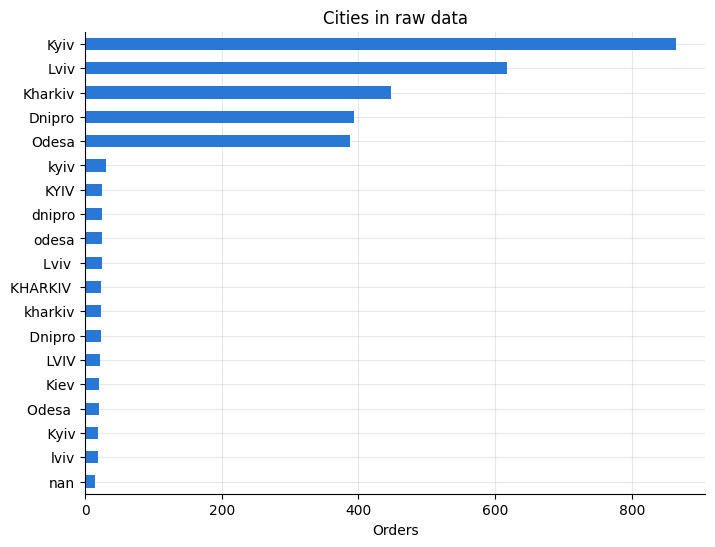

In [16]:
# 📈 Як виглядає «брудний» стовпець на графіку
raw["City"].value_counts(dropna=False).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Cities in raw data")
plt.xlabel("Orders")
plt.ylabel("")
plt.show()

7. Те саме місто записане по-різному: `"kyiv"`, `"KYIV"`, `" Kyiv"`, `"Kiev"`. Для pandas це **різні** значення, тож підрахунок по містах буде неправильним.

Виправляємо все по черзі. Працюватимемо з копією, щоб оригінал `raw` залишився для порівняння.

In [17]:
clean = raw.copy()

## Б2. Назви стовпців
Зробимо всі назви маленькими літерами, а пробіли замінимо на `_`. `.str` дає доступ до текстових команд (про них детальніше в Б4).

In [18]:
clean.columns = clean.columns.str.lower().str.replace(" ", "_")
clean = clean.rename(columns={"qty": "quantity"})

clean.columns

Index(['order_id', 'order_date', 'delivery_date', 'customer_id', 'city',
       'category', 'product', 'price', 'quantity', 'payment', 'channel',
       'status', 'rating'],
      dtype='object')

## Б3. Дублікати
`duplicated()` позначає рядки, які **повністю повторюють** якийсь попередній рядок.

In [19]:
print("Full duplicates:", clean.duplicated().sum())

clean[clean.duplicated(keep=False)].sort_values("order_id").head(6)   # keep=False показує обидві копії

Full duplicates: 25


,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
63,100064,10.01.2025,13.01.2025,C0075,Kharkiv,Sports,Yoga mat,700 UAH,NaN,Card,Website,Delivered,NaN
64,100064,10.01.2025,13.01.2025,C0075,Kharkiv,Sports,Yoga mat,700 UAH,NaN,Card,Website,Delivered,NaN
75,100075,12.01.2025,14.01.2025,C0045,Kharkiv,Home,Blanket,850 UAH,2.00,Card,App,Delivered,5.00
76,100075,12.01.2025,14.01.2025,C0045,Kharkiv,Home,Blanket,850 UAH,2.00,Card,App,Delivered,5.00
77,100076,12.01.2025,15.01.2025,C0394,Odesa,Clothing,T-shirt,450 UAH,2.00,Card,Website,Returned,NaN
78,100076,12.01.2025,15.01.2025,C0394,Odesa,Clothing,T-shirt,450 UAH,2.00,Card,Website,Returned,NaN


In [20]:
clean = clean.drop_duplicates().reset_index(drop=True)   # і нумеруємо рядки заново

print("Rows after removing duplicates:", len(clean))
print("Repeated order numbers:", clean["order_id"].duplicated().sum())

Rows after removing duplicates: 3000
Repeated order numbers: 0


💡 Перевірка `clean["order_id"].duplicated()` дивиться тільки на номер замовлення. Це корисно, бо дублікат може відрізнятися якоюсь дрібницею, але один номер замовлення не повинен траплятися двічі.

## Б4. Текст: прибираємо пробіли, вирівнюємо регістр

Текстові команди викликаються через **`.str`**:

| Команда | Що робить | `" kyiv "` → |
|---|---|---|
| `.str.strip()` | прибирає пробіли на початку і в кінці | `"kyiv"` |
| `.str.title()` | Перша Літера Велика | `" Kyiv "` |
| `.str.lower()` / `.str.upper()` | усі маленькі / усі великі | `" kyiv "` / `" KYIV "` |
| `.str.replace("a", "b")` | замінює частину тексту | |

Команди можна писати **ланцюжком**, одну за одною:

In [21]:
clean["city"] = clean["city"].str.strip().str.title()

clean["city"].unique()

array(['Kyiv', 'Odesa', 'Lviv', 'Dnipro', 'Kharkiv', nan, 'Kiev'],
      dtype=object)

Лишилася стара назва міста `Kiev`. Замінимо її на сучасну за словником, використавши метод `replace`:

In [22]:
clean["city"] = clean["city"].replace({"Kiev": "Kyiv"})

clean["city"].value_counts(dropna=False)     # dropna=False — показати й кількість пропусків (NaN)

,count
city,
Kyiv,950
Lviv,676
Kharkiv,490
Dnipro,440
Odesa,429
NaN,15


### 📈 «До» і «після»: два графіки поруч — `plt.subplots`

Щоб порівняти, зручно поставити графіки **поруч**. `plt.subplots(рядки, стовпці)` створює «сітку полотен»:
- `fig` — уся картинка;
- `axes` — полотна: `axes[0]` ліве, `axes[1]` праве.

Кожному `.plot()` вказуємо, на якому полотні малювати: `ax=axes[0]`.

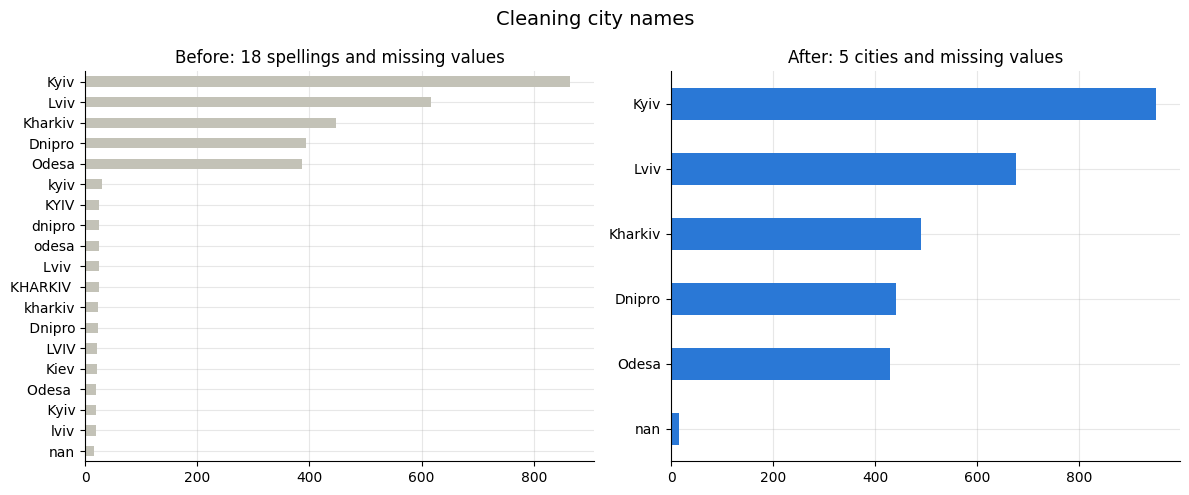

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))      # 1 рядок, 2 стовпці

raw["City"].value_counts(dropna=False).sort_values().plot(kind="barh", ax=axes[0], color="#c3c2b7")
axes[0].set_title("Before: 18 spellings and missing values")
axes[0].set_ylabel("")

clean["city"].value_counts(dropna=False).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("After: 5 cities and missing values")
axes[1].set_ylabel("")

fig.suptitle("Cleaning city names", fontsize=14)     # спільний заголовок для обох графіків
plt.tight_layout()                                    # акуратно розставити графіки, щоб не налазили
plt.show()

💡 Коли полотен кілька, заголовки задаємо через `axes[0].set_title(...)`, а не `plt.title(...)`: так зрозуміло, до якого графіка належить заголовок.

## Б5. Числа, записані як текст

Щоб перетворити `"1500 UAH"` на число 1500, потрібно:
1. прибрати « UAH» через `.str.replace()`;
2. змінити тип на ціле число через `.astype(int)`.

In [24]:
clean["price"] = clean["price"].str.replace(" UAH", "").astype(int)

print(clean["price"].dtype)
clean["price"].head()

int64


,price
0,950
1,4200
2,4200
3,2100
4,1100


💡 Якщо `.astype(int)` видає помилку, у стовпці ще лишився «сміттєвий» текст. Знайти його допоможе `clean["price"].unique()`.

## Б6. Дати

`pd.to_datetime()` перетворює текст на справжню дату. Параметр `format` підказує, як записана дата:

| Код | Що означає |
|---|---|
| `%d` | день (01–31) |
| `%m` | місяць (01–12) |
| `%Y` | рік з чотирьох цифр |

Наш формат `28.11.2025`, тобто `"%d.%m.%Y"`.

In [25]:
clean["order_date"] = pd.to_datetime(clean["order_date"], format="%d.%m.%Y")
clean["delivery_date"] = pd.to_datetime(clean["delivery_date"], format="%d.%m.%Y")

clean[["order_date", "delivery_date"]].head()

,order_date,delivery_date
0,2025-01-01,NaT
1,2025-01-01,2025-01-02
2,2025-01-01,2025-01-05
3,2025-01-01,2025-01-02
4,2025-01-01,2025-01-06


Порожні дати стали **`NaT`** (Not a Time): це «порожньо» для дат. Більше про дати — у блокноті 6.

## Б7. Пропуски

### Скільки їх?

In [ ]:
clean.isna().sum()

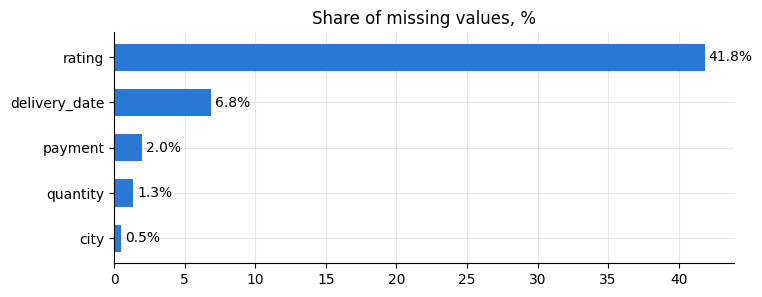

In [26]:
# 📈 «Карта пропусків»: частка порожніх клітинок у кожному стовпці, %
missing = (clean.isna().mean() * 100).sort_values()
missing = missing[missing > 0]                     # лише стовпці, де є пропуски

ax = missing.plot(kind="barh", figsize=(8, 3), width=0.6)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)    # fmt: 1 знак після коми і знак %
plt.title("Share of missing values, %")
plt.ylabel("")
plt.show()

### Що з ними робити?
Універсальної відповіді немає: для кожного стовпця вирішуємо окремо, **виходячи з бізнес-логіки**:

| Стовпець | Чому порожньо | Рішення |
|---|---|---|
| `delivery_date` | замовлення скасували, доставки не було | **залишаємо**: це правильні дані |
| `rating` | клієнт не поставив оцінку | **залишаємо**: вигадувати оцінку не можна |
| `quantity` | менеджер не вказав кількість, зазвичай це 1 штука | заповнюємо **1** |
| `payment` | спосіб оплати не зберігся | заповнюємо **`"Unknown"`** |
| `city` | місто не вказане | заповнюємо **`"Unknown"`** |

Заповнювати пропуски будемо через `fillna(значення)`:

In [27]:
clean["quantity"] = clean["quantity"].fillna(1).astype(int)   # після заповнення можна зробити цілими
clean["payment"] = clean["payment"].fillna("Unknown")
clean["city"] = clean["city"].fillna("Unknown")

clean.isna().sum()

,0
order_id,0
order_date,0
delivery_date,205
customer_id,0
city,0
category,0
product,0
price,0
quantity,0
payment,0


### ⚠️ Обережно з `dropna()`
`dropna()` **видаляє рядки**, у яких є хоч один пропуск. Подивіться, що станеться, якщо застосувати його бездумно:

In [28]:
print("Rows now:", len(clean))
print("Rows after dropna():", len(clean.dropna()))

Rows now: 3000
Rows after dropna(): 1745


Ми втратили б понад 40% замовлень лише через те, що клієнти не ставили оцінки! Тому `dropna()` використовують **тільки для конкретних стовпців**, де пропуск справді робить рядок непотрібним. Наприклад, `clean.dropna(subset=["customer_id"])` видалить лише рядки без клієнта.

## Б8. Фінальна перевірка і збереження

In [29]:
clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       3000 non-null   int64         
 1   order_date     3000 non-null   datetime64[ns]
 2   delivery_date  2795 non-null   datetime64[ns]
 3   customer_id    3000 non-null   object        
 4   city           3000 non-null   object        
 5   category       3000 non-null   object        
 6   product        3000 non-null   object        
 7   price          3000 non-null   int64         
 8   quantity       3000 non-null   int64         
 9   payment        3000 non-null   object        
 10  channel        3000 non-null   object        
 11  status         3000 non-null   object        
 12  rating         1745 non-null   float64       
dtypes: datetime64[ns](2), float64(1), int64(3), object(7)
memory usage: 304.8+ KB


Тепер ціна — число, дати — дати, дублікатів немає, а пропуски лишилися тільки там, де вони мають сенс. Зберігаємо результат:

In [30]:
clean.to_csv("sales_clean.csv", index=False)
print("Saved sales_clean.csv:", clean.shape)

Saved sales_clean.csv: (3000, 13)


### 🧹 Чек-лист очищення даних
1. `info()`, `head()`, `unique()`: шукаємо проблеми.
2. Назви стовпців → зручний вигляд.
3. Дублікати → `duplicated()`, `drop_duplicates()`.
4. Текст → `.str.strip()`, `.str.title()`, `replace()`.
5. Типи → `.astype()`, `pd.to_datetime()`.
6. Пропуски → `isna().sum()`, вирішуємо для кожного стовпця окремо: `fillna()`, `dropna(subset=...)` або залишаємо.
7. Ще раз `info()`: перевіряємо результат.

---
# ✍️ Практика

### Частина А: нові стовпці (працюємо з `df`)

**Завдання 1.** Під час розпродажу на всі товари діє знижка 10%. Додайте стовпець `sale_price`: ціна зі знижкою, округлена до цілих гривень.

In [31]:
# Створюємо новий стовпець із ціною після знижки 10%
df["sale_price"] = (df["price"] * 0.9).round().astype(int)

# Показуємо перші 5 рядків для перевірки
df[["product", "price", "sale_price"]].head()

,product,price,sale_price
0,Dumbbells 5 kg,950,855
1,Smartwatch,4200,3780
2,Smartwatch,4200,3780
3,Bluetooth speaker,2100,1890
4,Desk lamp,1100,990


**Завдання 2.** Додайте стовпець `basket`: `"Single item"`, якщо `quantity` дорівнює 1, і `"Multiple items"` в іншому випадку. Скільки замовлень у кожній групі?

In [32]:
# Створюємо новий стовпець залежно від кількості товарів
df["basket"] = np.where(df["quantity"] == 1, "Single item", "Multiple items")

# Рахуємо кількість замовлень у кожній групі
df["basket"].value_counts()

# Висновок: 2194 замовлення містять один товар (Single item),
# а 806 замовлень — декілька товарів (Multiple items).
# Замовлень з одним товаром значно більше.

,count
basket,
Single item,2194
Multiple items,806


**Завдання 3.** Додайте стовпець `is_problem`: `True`, якщо замовлення скасоване або повернене. Скільки таких замовлень?

In [33]:
# Створюємо стовпець, який визначає проблемні замовлення
df["is_problem"] = df["status"].isin(["Cancelled", "Returned"])

# Рахуємо кількість проблемних замовлень
df["is_problem"].sum()

# Висновок: знайдено 336 проблемних замовлень
# зі статусами Cancelled або Returned.


np.int64(336)

### Частина Б: очищення списку клієнтів

Файл **`customers_raw.csv`** — «брудний» список клієнтів.

**Завдання 4.** Прочитайте файл у змінну `cust`. Подивіться на дані й випишіть, які проблеми ви знайшли.

In [37]:
# Завантажуємо файл із даними клієнтів
cust = pd.read_csv("customers_raw.csv")

# Дивимося перші 5 рядків таблиці
display(cust.head())

# Перевіряємо кількість рядків, типи даних і пропуски
cust.info()

# Дивимося всі унікальні назви міст
cust["city"].unique()

# Висновок:
# 1. У стовпці age є 12 пропущених значень.
# 2. Назви міст записані в різному регістрі.
# 3. У назвах міст зустрічаються зайві пробіли.
# 4. registration_date зберігається як текст, а не дата.
# Дані потребують очищення.

,customer_id,name,city,age,registration_date
0,C0001,Sofiia,Lviv,29.00,05/05/2023
1,C0002,Tetiana,Dnipro,27.00,24/12/2024
2,C0003,Andrii,Kharkiv,35.00,22/12/2024
3,C0004,Iryna,Dnipro,29.00,23/02/2023
4,C0005,Sofiia,Odesa,40.00,10/11/2024


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 408 entries, 0 to 407
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        408 non-null    object 
 1   name               408 non-null    object 
 2   city               408 non-null    object 
 3   age                396 non-null    float64
 4   registration_date  408 non-null    object 
dtypes: float64(1), object(4)
memory usage: 16.1+ KB


array(['Lviv ', 'Dnipro', 'Kharkiv', 'Odesa', 'Kyiv', 'Lviv', 'Kharkiv ',
       'odesa', 'kharkiv', 'KHARKIV', 'lviv', 'Kyiv ', 'DNIPRO', 'KYIV',
       'LVIV', 'kyiv', 'Odesa ', 'ODESA', 'Dnipro ', 'dnipro'],
      dtype=object)

**Завдання 5.** Видаліть повні дублікати. Скільки їх було?

In [38]:
# Рахуємо кількість повних дублікатів
print("Кількість дублікатів:", cust.duplicated().sum())

# Видаляємо дублікати та оновлюємо нумерацію рядків
cust = cust.drop_duplicates().reset_index(drop=True)

# Перевіряємо кількість рядків після очищення
print("Залишилося клієнтів:", len(cust))

# Висновок: знайдено та видалено 8 повних дублікатів.
# Кількість рядків зменшилася з 408 до 400.

Кількість дублікатів: 8
Залишилося клієнтів: 400


**Завдання 6.** Приведіть імена (`name`) і міста (`city`) до однакового вигляду: без зайвих пробілів, з великої літери. Перевірте міста через `value_counts()`.

In [39]:
# Прибираємо зайві пробіли та виправляємо регістр імен
cust["name"] = cust["name"].str.strip().str.title()

# Прибираємо зайві пробіли та виправляємо регістр міст
cust["city"] = cust["city"].str.strip().str.title()

# Рахуємо кількість клієнтів у кожному місті
cust["city"].value_counts()

# Висновок: імена та назви міст приведено до єдиного формату.
# Видалено зайві пробіли та виправлено регістр літер.
# Після очищення залишилося 5 унікальних міст.
# Найбільше клієнтів у Kyiv — 131, найменше у Dnipro — 56.

,count
city,
Kyiv,131
Lviv,89
Kharkiv,66
Odesa,58
Dnipro,56


**Завдання 7.** Заповніть пропуски у віці (`age`) **медіанним** віком і зробіть стовпець цілим числом.

In [40]:
# Знаходимо медіанний вік клієнтів
median_age = cust["age"].median()

# Заповнюємо пропуски медіаною та перетворюємо вік на цілі числа
cust["age"] = cust["age"].fillna(median_age).astype(int)

# Перевіряємо результат
print("Медіанний вік:", median_age)
print("Залишилося пропусків:", cust["age"].isna().sum())
print("Тип даних:", cust["age"].dtype)

# Висновок: пропущені значення віку заповнено медіаною (32 роки).
# Після очищення пропусків не залишилося.
# Тип даних стовпця age змінено на цілі числа (int64).

Медіанний вік: 32.0
Залишилося пропусків: 0
Тип даних: int64


**Завдання 8 ⭐.** Перетворіть `registration_date` на дату (формат `день/місяць/рік`). Знайдіть найранішу і найпізнішу дату реєстрації. Наприкінці перевірте всю таблицю через `info()`.

In [41]:
# Перетворюємо текст на справжній тип дати
cust["registration_date"] = pd.to_datetime(
    cust["registration_date"], format="%d/%m/%Y"
)

# Знаходимо найранішу дату реєстрації
print("Найраніша дата:", cust["registration_date"].min())

# Знаходимо найпізнішу дату реєстрації
print("Найпізніша дата:", cust["registration_date"].max())

# Перевіряємо типи даних усієї таблиці
cust.info()

# Висновок: стовпець registration_date перетворено на тип datetime.
# Найраніша реєстрація: 04.01.2022.
# Найпізніша реєстрація: 27.12.2024.
# Таблиця містить 400 рядків і 5 стовпців без пропусків.

Найраніша дата: 2022-01-04 00:00:00
Найпізніша дата: 2024-12-27 00:00:00
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   customer_id        400 non-null    object        
 1   name               400 non-null    object        
 2   city               400 non-null    object        
 3   age                400 non-null    int64         
 4   registration_date  400 non-null    datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 15.8+ KB


**Завдання 9 📈.** Побудуйте два графіки поруч: кількість клієнтів по містах **до** очищення (з файлу `customers_raw.csv`) і **після** (таблиця `cust`).

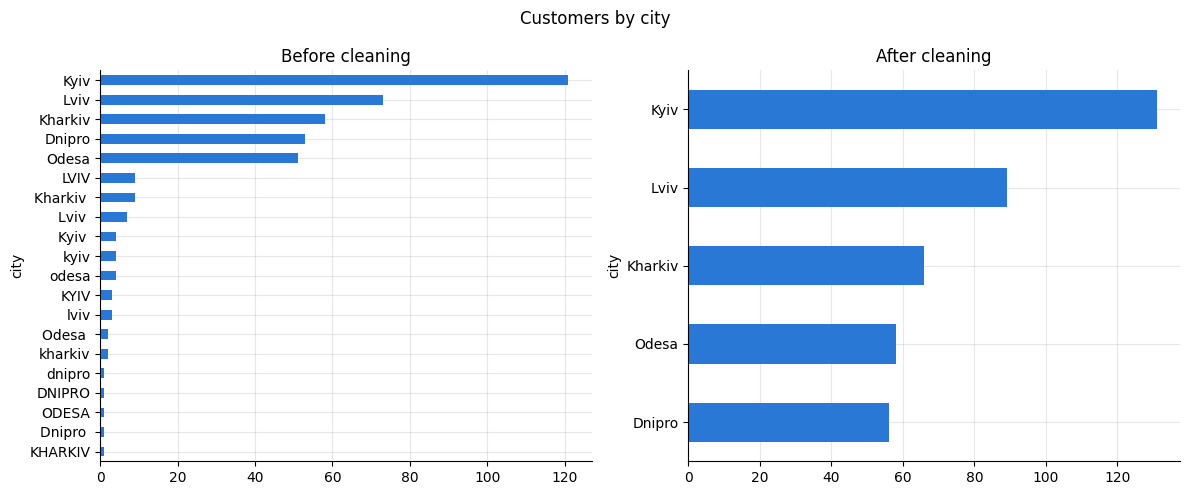

In [42]:
# Завантажуємо початкові дані до очищення
cust_raw = pd.read_csv("customers_raw.csv")

# Створюємо два графіки поруч
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Лівий графік — до очищення
cust_raw["city"].value_counts().sort_values().plot(
    kind="barh", ax=axes[0]
)
axes[0].set_title("Before cleaning")

# Правий графік — після очищення
cust["city"].value_counts().sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("After cleaning")

# Додаємо загальний заголовок
fig.suptitle("Customers by city")

# Покращуємо розташування графіків
plt.tight_layout()
plt.show()

# Висновок: до очищення назви міст мали різний регістр
# і зайві пробіли, тому відображалися окремими категоріями.
# Після очищення залишилося 5 унікальних міст.
# Найбільше клієнтів у Kyiv (131), найменше у Dnipro (56).
# Дані після очищення стали придатними для коректного аналізу.

**Завдання 10 📈⭐.** Побудуйте дві гістограми віку клієнтів поруч, з інтервалом в 1 рік (`bins=range(18, 66)`): ліворуч вік **до** заповнення пропусків (з файлу `customers_raw.csv`), праворуч **після** (таблиця `cust`). На обох графіках проведіть вертикальну лінію на медіані. Що змінилося біля лінії? Чому так сталося?

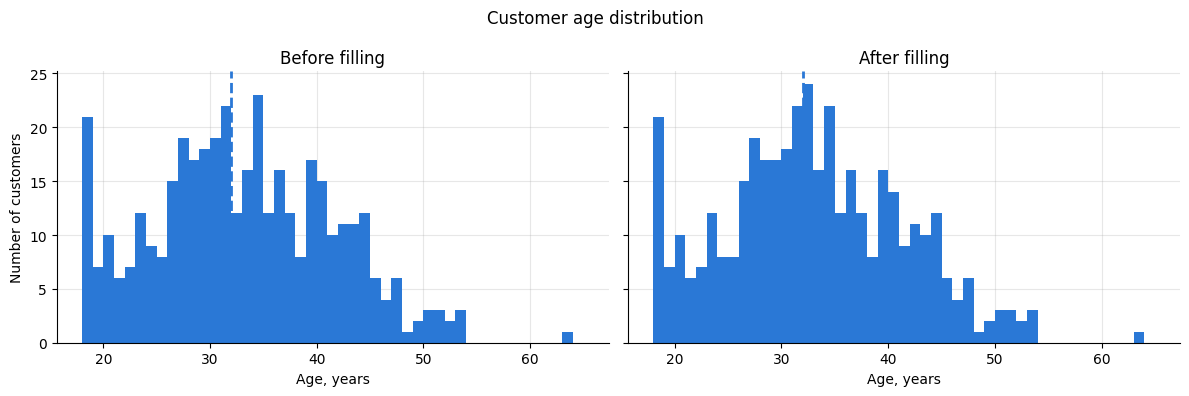

In [44]:
# Завантажуємо початкові дані
cust_raw = pd.read_csv("customers_raw.csv")

# Знаходимо медіанний вік
median_age = cust["age"].median()

# Створюємо два графіки поруч
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# Лівий графік — до заповнення пропусків
cust_raw["age"].plot(kind="hist", bins=range(18, 66), ax=axes[0])
axes[0].set_title("Before filling")
axes[0].set_ylabel("Number of customers")

# Правий графік — після заповнення пропусків
cust["age"].plot(kind="hist", bins=range(18, 66), ax=axes[1])
axes[1].set_title("After filling")

# Додаємо вертикальну лінію медіани на обох графіках
for ax in axes:
    ax.axvline(median_age, linestyle="--", linewidth=2)
    ax.set_xlabel("Age, years")

# Загальний заголовок
fig.suptitle("Customer age distribution")

# Показуємо графіки
plt.tight_layout()
plt.show()

# Висновок: медіанний вік клієнтів становить 32 роки.
# Після заповнення пропусків кількість значень віку 32 роки зросла.
# Загальний розподіл віку залишився подібним.
# На відмінності між графіками також вплинуло видалення дублікатів.

---
# 📋 Шпаргалка блокнота 3

**Нові стовпці**

| Код | Що робить |
|---|---|
| `df["new"] = df["a"] * df["b"]` | стовпець-формула |
| `np.where(умова, "yes", "no")` | «ЯКЩО» з двома варіантами |
| `pd.cut(df["col"], bins=[...], labels=[...])` | розбити числа на групи |
| `df["col"].map({"a": "x", "b": "y"})` | заміна за словником (немає в словнику → NaN) |
| `df.rename(columns={"old": "new"})` | перейменувати стовпці |
| `df.drop(columns=["col"])` | видалити стовпці |

**Очищення**

| Код | Що робить |
|---|---|
| `df.columns.str.lower().str.replace(" ", "_")` | привести назви стовпців до ладу |
| `df.duplicated().sum()`, `df.drop_duplicates()` | знайти / видалити дублікати |
| `.str.strip()`, `.str.title()`, `.str.lower()` | пробіли, регістр |
| `.str.replace("a", "b")` | замінити частину тексту |
| `df["col"].replace({"a": "b"})` | замінити значення цілком |
| `.astype(int)` / `.astype(float)` | змінити тип |
| `pd.to_datetime(df["col"], format="%d.%m.%Y")` | текст → дата |
| `df.isna().sum()` | кількість пропусків |
| `df["col"].fillna(значення)` | заповнити пропуски |
| `df.dropna(subset=["col"])` | видалити рядки з пропуском у конкретному стовпці |

**📈 Графіки**

| Код | Що робить |
|---|---|
| `fig, axes = plt.subplots(1, 2, figsize=(12, 5))` | два графіки поруч |
| `series.plot(..., ax=axes[0])` | малювати на конкретному полотні |
| `axes[0].set_title("...")` | заголовок конкретного графіка |
| `fig.suptitle("...")` | спільний заголовок |
| `plt.tight_layout()` | розставити графіки без накладань |
| `plt.axvline(x, linestyle="--")` / `plt.axhline(y)` | вертикальна / горизонтальна лінія-орієнтир |
| `plt.text(x, y, "text")` | напис на графіку |
| `plt.xlim(0, 10000)` / `plt.ylim(...)` | межі осей |
| `ax.bar_label(ax.containers[0], fmt="%.1f%%")` | підписи з форматом (тут: відсотки) |
| `.sort_index()` перед графіком | зберегти природний порядок груп |

---
### ➡️ Далі: блокнот 4 «Групування та зведені таблиці»
Найпотужніший інструмент аналітика: виручка по містах, середній чек по каналах, зведені таблиці як в Excel. А 📈 графіки з групувань: згруповані та складені стовпчики, теплові таблиці.

In [ ]:
# @title 💡 Розв'язки практики: відкривайте, лише якщо справді застрягли
# Спершу спробуйте розв'язати кожне завдання самостійно в клітинках «Ваш код тут».

# ========== Частина А ==========

# ---------- Завдання 1 ----------
df["sale_price"] = (df["price"] * 0.9).round().astype(int)
display(df[["product", "price", "sale_price"]].head())

# ---------- Завдання 2 ----------
df["basket"] = np.where(df["quantity"] == 1, "Single item", "Multiple items")
display(df["basket"].value_counts())

# ---------- Завдання 3 ----------
df["is_problem"] = df["status"].isin(["Cancelled", "Returned"])
print("Problem orders:", df["is_problem"].sum())    # сума True — це їхня кількість

# ========== Частина Б ==========

# ---------- Завдання 4 ----------
cust = pd.read_csv("customers_raw.csv")
cust.info()
print(cust["city"].unique())
display(cust.head())
# Проблеми: є пропуски у віці, міста й імена записані по-різному,
# дата реєстрації — текст у форматі день/місяць/рік, можливі дублікати.

# ---------- Завдання 5 ----------
print("Duplicates:", cust.duplicated().sum())
cust = cust.drop_duplicates().reset_index(drop=True)
print("Customers left:", len(cust))

# ---------- Завдання 6 ----------
cust["name"] = cust["name"].str.strip().str.title()
cust["city"] = cust["city"].str.strip().str.title()
display(cust["city"].value_counts())

# ---------- Завдання 7 ----------
median_age = cust["age"].median()
print("Median age:", median_age)

cust["age"] = cust["age"].fillna(median_age).astype(int)
print("Missing ages:", cust["age"].isna().sum())

# ---------- Завдання 8 ⭐ ----------
cust["registration_date"] = pd.to_datetime(cust["registration_date"], format="%d/%m/%Y")

print("First registration:", cust["registration_date"].min().date())
print("Last registration:", cust["registration_date"].max().date())
cust.info()

# ---------- Завдання 9 📈 ----------
cust_raw = pd.read_csv("customers_raw.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cust_raw["city"].value_counts().sort_values().plot(kind="barh", ax=axes[0], color="#c3c2b7")
axes[0].set_title("Before cleaning")
axes[0].set_ylabel("")

cust["city"].value_counts().sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("After cleaning")
axes[1].set_ylabel("")

fig.suptitle("Customers by city", fontsize=14)
plt.tight_layout()
plt.show()

# ---------- Завдання 10 📈⭐ ----------
cust_raw = pd.read_csv("customers_raw.csv")
median_age = cust["age"].median()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)    # sharey=True — однакова вісь Y на обох графіках

cust_raw["age"].plot(kind="hist", bins=range(18, 66), ax=axes[0], color="#c3c2b7")
axes[0].set_title("Before filling")
axes[0].set_ylabel("Number of customers")

cust["age"].plot(kind="hist", bins=range(18, 66), ax=axes[1])
axes[1].set_title("After filling with the median")
axes[1].set_ylabel("")

for ax in axes:
    ax.axvline(median_age, color="#e34948", linestyle="--", linewidth=1.5)
    ax.set_xlabel("Age, years")

fig.suptitle(f"Customer age (median: {median_age:.0f})", fontsize=14)
plt.tight_layout()
plt.show()

# До заповнення на віці 32 було 12 клієнтів, після — 24: стовпчик на медіані виріс удвічі,
# бо ми додали туди 12 однакових «вигаданих» значень.
# Заповнення медіаною зручне, але спотворює розподіл. Пам'ятайте про це, якщо пропусків багато.
